# Hong Kong Mortality Rates (2000–2025)

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

START_YEAR = 2000
END_YEAR = 2025

RAW = Path("raw")
POP_FILE = RAW / "Table 110-01001_en.xlsx"
DEATHS_FILE = RAW / "Table 115-01022_en.xlsx"

pop_raw = pd.read_excel(POP_FILE, header=None)
deaths_raw = pd.read_excel(DEATHS_FILE, header=None)

In [5]:
pop_raw.head(10)

,0,1,2,3,4,5,6,7,8,9,...,254,255,256,257,258,259,260,261,262,263
0,Table 110-01001 : Population by sex and age group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,,NaN,Population,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Number ('000),NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Year,NaN,1961,NaN,1962,NaN,1963,NaN,1964,NaN,...,NaN,2022,NaN,2023,NaN,2024,NaN,2025,NaN,2026
5,Reference time-point,NaN,Mid-year,Year-end,Mid-year,Year-end,Mid-year,Year-end,Mid-year,Year-end,...,Year-end,Mid-year,Year-end,Mid-year,Year-end,Mid-year,Year-end,Mid-year,Year-end,Mid-year p
6,Sex,Age group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Male,0 - 4,268.4,N.A.,271.9,N.A.,275.6,N.A.,275.3,N.A.,...,1.5,1.5,1.4,1.4,1.3,1.3,1.3,1.2,1.2,1.1
8,NaN,5 - 9,221.6,N.A.,243.9,N.A.,245.1,N.A.,255.4,N.A.,...,2,1.9,1.8,1.8,1.8,1.8,1.8,1.7,1.7,1.7
9,NaN,10 - 14,161.1,N.A.,178,N.A.,191.6,N.A.,202.8,N.A.,...,2,2,2.1,2.1,2.1,2.1,2,2,2,2


### Population table

In [6]:
pop_years = pd.to_numeric(pop_raw.iloc[4], errors='coerce')

# Row 3: columns 2 to 132 are population in thousands, and column 133 onwards is population '%'
pop_measure = pop_raw.iloc[3].ffill() # Forward filling copies the label across the blank cells next to it. Typing the labels causes risk of mislabelling, not good practice.
pop_timepoint = pop_raw.iloc[5]

keep_cols = []
for i in pop_raw.columns[2:]:
    if pop_measure[i] == "Number ('000)" and pop_timepoint[i] == "Mid-year" and pop_years[i] >= START_YEAR and pop_years[i] <= END_YEAR: # Keep population in thousands. Deaths are counted over the whole calendar year, so the mid-year population kinda more represents avg number of people at risk

        keep_cols.append(i)



In [7]:
pop_body = pop_raw.iloc[7:, [0, 1] + keep_cols].copy() # Data starts at row 7 in the population file

new_names = ['sex', 'age']
for c in keep_cols:
    year = int(pop_years[c])
    new_names.append(year)
pop_body.columns = new_names

pop_body.iloc[:,0] = pop_body.iloc[:,0].ffill()   # Sex is only written on the first row of each block

pop_body = pop_body[pop_body['age'].notna()]

pop_body.head(5)

,sex,age,2000,2001,2002,2003,2004,2005,2006,2007,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
7,Male,0 - 4,153.4,142,130.3,122.8,118.3,114.4,110.4,111.3,...,144.8,141.2,138.2,134.9,127,117.5,109.4,104.1,97.7,90.3
8,Male,5 - 9,208.8,205.2,200.8,191.6,182.8,171.3,162.3,152.6,...,151.2,157.1,158.7,160,156.4,148.8,139.1,138.2,134.9,129.2
9,Male,10 - 14,221.9,220.9,222.6,221.1,217,213.1,211.3,209.9,...,132.3,134.9,141.3,145.6,147.2,149.7,150.5,161.7,155.5,149.6
10,Male,15 - 19,236.4,229.3,224.8,219.7,221.4,220.2,222.3,226.1,...,176.5,161.4,151.8,143.6,137.5,134.9,137.3,150,149.3,144.3
11,Male,20 - 24,224.7,225.1,222.7,221.8,226,226.4,225.6,221.3,...,220.3,216.5,208.7,195.6,182.6,164.7,153,159.1,154.1,150.7


In [8]:
pop_long = pop_body.melt(id_vars=['sex', 'age'], var_name='year', value_name='thousands')

pop_long['year'] = pop_long['year'].astype(int)

pop_long['population'] = pd.to_numeric(pop_long['thousands'], errors='coerce')*1000

# Round() first, or else 129.2*1000 becomes to 129199.99999999999, and astype(int) would make it 129199.
pop_long['population'] = pop_long['population'].round().astype(int)

population = pop_long[pop_long['age']!='All age groups']
population = population[["year", "sex", "age", "population"]].reset_index(drop=True)

# The source's own 'All age groups' rows: used as the denominator of the crude rate
pop_total = pop_long.loc[pop_long['age'] == 'All age groups', ['year', 'sex', 'population']].reset_index(drop=True)

In [9]:
population.head(5)

,year,sex,age,population
0,2000,Male,0 - 4,153400
1,2000,Male,5 - 9,208800
2,2000,Male,10 - 14,221900
3,2000,Male,15 - 19,236400
4,2000,Male,20 - 24,224700


## Deaths table

In [10]:
deaths_raw.head(10)

,0,1,2,3,4,5,6,7,8,9,...,57,58,59,60,61,62,63,64,65,66
0,Table 115-01022 : Deaths by sex and age group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,,NaN,Number of deaths (1) (2),NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,Number,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Year,NaN,1961,1962,1963,1964,1965,1966,1967,1968,...,2016.0,2017.0,2018.0,2019.0,2020.0,2021.0,2022.0,2023.0,2024.0,2025.0
5,Sex,Age group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Male,< 1,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,...,59.0,50.0,41.0,42.0,51.0,27.0,33.0,22.0,39.0,23.0
7,NaN,1 - 4,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,...,21.0,15.0,11.0,16.0,13.0,13.0,13.0,14.0,13.0,13.0
8,NaN,5 - 9,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,...,12.0,18.0,12.0,6.0,10.0,10.0,12.0,9.0,7.0,12.0
9,NaN,10 - 14,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,N.A.,...,11.0,15.0,16.0,13.0,17.0,20.0,15.0,17.0,11.0,20.0


In [11]:
death_years = pd.to_numeric(deaths_raw.iloc[4], errors='coerce')

death_cols = []
for j in deaths_raw.columns[2:]:
    if death_years[j] >= START_YEAR and death_years[j] <= END_YEAR:
        death_cols.append(j)

death_body = deaths_raw.iloc[6:, [0, 1] + death_cols].copy() # Data starts at row 6 in the deaths file

new_names = ['sex', 'age']
for n in death_cols:
    year = int(death_years[n])
    new_names.append(year)
death_body.columns = new_names

death_body['sex'] = death_body['sex'].ffill()
death_body = death_body[death_body["age"].notna()]

In [12]:
death_body.head(5)

,sex,age,2000,2001,2002,2003,2004,2005,2006,2007,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
6,Male,< 1,90.0,69.0,61.0,57.0,65.0,78.0,64.0,67.0,...,59.0,50.0,41.0,42.0,51.0,27.0,33.0,22.0,39.0,23.0
7,Male,1 - 4,28.0,31.0,22.0,23.0,18.0,15.0,22.0,12.0,...,21.0,15.0,11.0,16.0,13.0,13.0,13.0,14.0,13.0,13.0
8,Male,5 - 9,25.0,27.0,22.0,20.0,15.0,16.0,20.0,15.0,...,12.0,18.0,12.0,6.0,10.0,10.0,12.0,9.0,7.0,12.0
9,Male,10 - 14,33.0,26.0,38.0,23.0,24.0,22.0,25.0,23.0,...,11.0,15.0,16.0,13.0,17.0,20.0,15.0,17.0,11.0,20.0
10,Male,15 - 19,45.0,61.0,57.0,56.0,57.0,57.0,42.0,46.0,...,38.0,45.0,32.0,37.0,28.0,27.0,39.0,45.0,33.0,36.0


In [13]:
deaths_long = death_body.melt(id_vars=['age','sex'], var_name='year', value_name='deaths')

deaths_long['year'] = deaths_long['year'].astype(int)
deaths_long['deaths'] = pd.to_numeric(deaths_long['deaths'], errors='coerce')
deaths_long['deaths'] = deaths_long['deaths'].astype(int)

print("Both sexes all years, Uuknown-age deaths dropped:", deaths_long.loc[(deaths_long['age'] == 'Unknown') & (deaths_long['sex'] == 'Both sexes'), 'deaths'].sum())

deaths = deaths_long[(deaths_long['age'] != 'Unknown') & (deaths_long['age'] != 'All age groups')]
deaths = deaths[['year', 'sex', 'age', 'deaths']].reset_index(drop=True)

# 'All age groups' include unknown age and unknown sex
deaths_total = deaths_long.loc[deaths_long['age'] == 'All age groups', ['year', 'sex', 'deaths']].reset_index(drop=True)
unknown_age = deaths_long.loc[deaths_long['age'] == 'Unknown', ['year', 'sex', 'deaths']]

unk = unknown_age[unknown_age['sex'] == 'Both sexes'].set_index('year')['deaths']
tot = deaths_total[deaths_total['sex'] == 'Both sexes'].set_index('year')['deaths']
print(f"Both sexes, unknown-age deaths as share of all deaths: at most {(unk / tot).max() * 100:.2f}% in any one year")

Both sexes all years, Uuknown-age deaths dropped: 861
Both sexes, unknown-age deaths as share of all deaths: at most 0.13% in any one year


In [14]:
deaths.head(5)

,year,sex,age,deaths
0,2000,Male,< 1,90
1,2000,Male,1 - 4,28
2,2000,Male,5 - 9,25
3,2000,Male,10 - 14,33
4,2000,Male,15 - 19,45


## Combine and 'tidy' data

Death counts had age groups `< 1` and `1 - 4` but population counts had just age group 0–4. So need to combine those 2 age groups in death counts.

In [15]:
deaths['age'] = deaths['age'].replace({'< 1': '0 - 4', '1 - 4': '0 - 4'})
deaths = deaths.groupby(['year', 'sex', 'age'], as_index=False)["deaths"].sum()

keys = ['year', 'sex', 'age']
mortality = population.merge(deaths, on=keys, how='inner', validate='one_to_one')

# Checking no data lost
print(len(mortality) == len(deaths))
print(len(population) == len(deaths))

mortality['rate_per_100k'] = mortality['deaths'] / mortality['population'] * 100000


True
True


### Both-sexes (which include deaths of unknown sex)

In [16]:
overall = mortality[mortality['sex'] == 'Both sexes'].reset_index(drop=True)

AGE_ORDER = list(population['age'].unique())   # Natural age order (cus text sorting would've put "5 - 9" after "45 - 49")
AGE_ORDER

['0 - 4',
 '5 - 9',
 '10 - 14',
 '15 - 19',
 '20 - 24',
 '25 - 29',
 '30 - 34',
 '35 - 39',
 '40 - 44',
 '45 - 49',
 '50 - 54',
 '55 - 59',
 '60 - 64',
 '65 - 69',
 '70 - 74',
 '75 - 79',
 '80 - 84',
 '≥85']

### Results

Text(0, 0.5, 'Deaths per 100,000 people (log scale)')

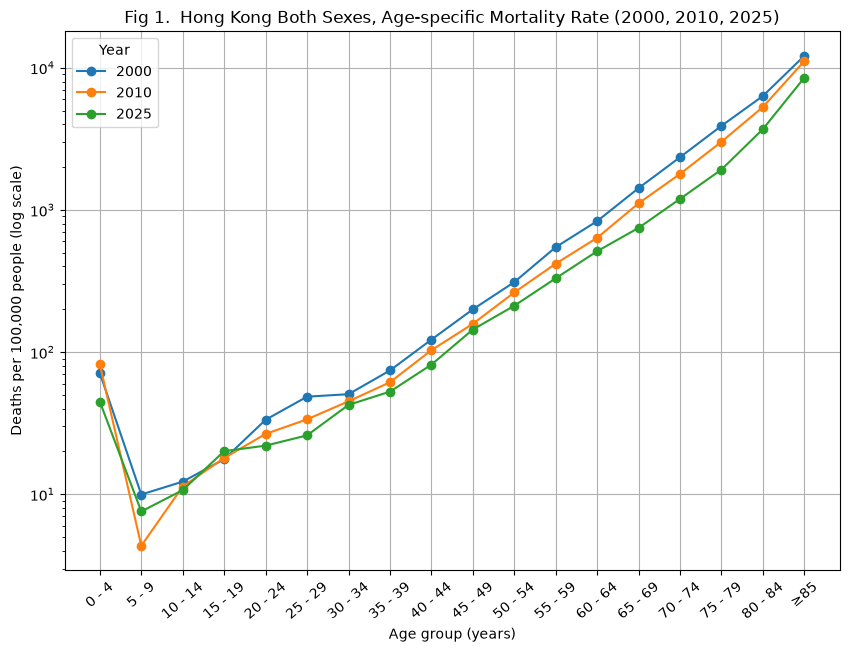

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))

for year in (2000, 2010, 2025): 
    one_year = overall[overall['year'] == year]
    ax.plot(AGE_ORDER, one_year['rate_per_100k'], marker='o', label=str(year))


ax.legend(title='Year')
ax.set_yscale('log')
ax.tick_params(axis='x', rotation=40)
ax.grid()

ax.set_title("Fig 1.  Hong Kong Both Sexes, Age-specific Mortality Rate (2000, 2010, 2025)")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Deaths per 100,000 people (log scale)")



Text(0, 0.5, 'Deaths per 100,000 people (log scale)')

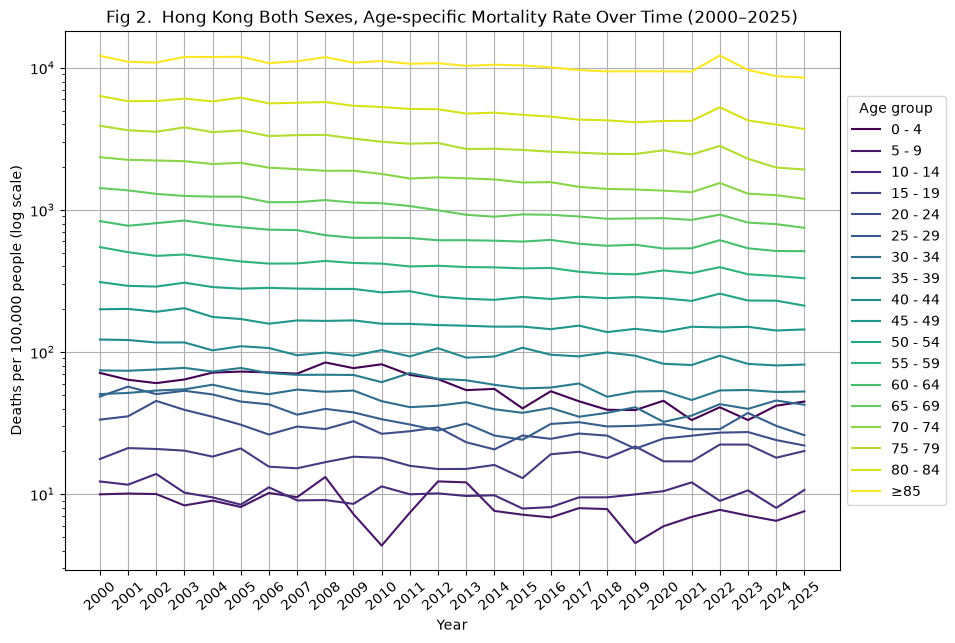

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))

colours = plt.cm.viridis(np.linspace(0, 1, len(AGE_ORDER)))
for age, colour in zip(AGE_ORDER, colours):
    one_age = overall[overall["age"] == age]
    ax.plot(
        one_age['year'],
        one_age['rate_per_100k'],
        color=colour,
        label=age,
    )


ax.set_yscale("log")
ax.set_xticks(range(START_YEAR, END_YEAR + 1))
ax.tick_params(axis='x', rotation=40)
ax.grid()

ax.legend(title="Age group", loc="center left", bbox_to_anchor=(1, 0.5))
ax.set_title(f"Fig 2.  Hong Kong Both Sexes, Age-specific Mortality Rate Over Time ({START_YEAR}–{END_YEAR})")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 people (log scale)")



In [19]:
summary = overall[overall['year'].isin([2000, 2010, 2020, 2025])].pivot(index='age', columns='year', values='rate_per_100k')
summary.loc[AGE_ORDER].round(1)

year,2000,2010,2020,2025
age,,,,
0 - 4,71.3,81.9,45.4,44.8
5 - 9,10.0,4.3,5.9,7.6
10 - 14,12.3,11.3,10.5,10.7
15 - 19,17.6,18.0,17.0,20.1
20 - 24,33.4,26.6,24.6,22.0
25 - 29,48.6,33.7,31.0,26.0
30 - 34,50.6,45.1,32.2,42.5
35 - 39,74.2,61.3,53.1,52.7
40 - 44,122.3,103.1,82.6,81.6


In [20]:
overall.groupby('year')['deaths'].sum().to_frame("deaths, both sexes (known age)").T

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
"deaths, both sexes (known age)",33732,33353,34243,36924,36869,38797,37415,39427,41754,41145,...,46871,46771,47348,48902,50633,51338,63676,54709,52361,51415


### Crude vs WHO Age-standardised

- Crude rate = all deaths ÷ total population × 100,000, using the source's `Both sexes` / `All age groups` row. This includes deaths of unknown age and unknown sex.
- Age-standardised rate: reweights Hong Kong's age-specific rates to the WHO World Standard Population (2000–2025). Only used known-age deaths only, because I can't assign a death of unknown age to an age group.


In [21]:
WHO_WORLD_STANDARD = {
    "0 - 4":   0.0886, "5 - 9":   0.0869, "10 - 14": 0.0860, "15 - 19": 0.0847,
    "20 - 24": 0.0822, "25 - 29": 0.0793, "30 - 34": 0.0761, "35 - 39": 0.0715,
    "40 - 44": 0.0659, "45 - 49": 0.0604, "50 - 54": 0.0537, "55 - 59": 0.0455,
    "60 - 64": 0.0372, "65 - 69": 0.0296, "70 - 74": 0.0221, "75 - 79": 0.0152,
    "80 - 84": 0.00910, "≥85": 0.00635,
} # all WHO age groups after 85+ combined, 0.440+0.150+0.040+0.005=0.635%

WHO_W = pd.Series(WHO_WORLD_STANDARD) / sum(WHO_WORLD_STANDARD.values())   # published weights sum to 100.035%

latest = overall[overall['year'] == END_YEAR].set_index('age').loc[AGE_ORDER]
crude = (deaths_total.query("year == @END_YEAR and sex == 'Both sexes'")['deaths'].iloc[0]
         / pop_total.query("year == @END_YEAR and sex == 'Both sexes'")['population'].iloc[0] * 100_000)
asr = (latest['rate_per_100k'] * WHO_W).sum()   # age-specific rates use known-age deaths

pop_latest = population[
    (population['year'] == END_YEAR) & (population['sex'] == 'Both sexes')
].set_index('age').loc[AGE_ORDER]
over_65 = ["65 - 69", "70 - 74", "75 - 79", "80 - 84", "≥85"]
hk_65 = pop_latest.loc[over_65, 'population'].sum() / pop_latest['population'].sum()
who_65 = sum(WHO_W[a] for a in over_65)


print(f"Crude death rate ({END_YEAR}): {crude:.0f} per 100k")
print(f"After WHO Age-standardisation, death rate ({END_YEAR}): {asr:.0f} per 100k")
print(f"Share of population aged 65+ in Hong Kong ({END_YEAR}): {hk_65 * 100:.1f}%")
print(f"Share of population aged 65+ in WHO standard population: {who_65 * 100:.1f}%")

Crude death rate (2025): 686 per 100k
After WHO Age-standardisation, death rate (2025): 243 per 100k
Share of population aged 65+ in Hong Kong (2025): 23.8%
Share of population aged 65+ in WHO standard population: 8.2%


Text(0, 0.5, 'Deaths per 100,000 people')

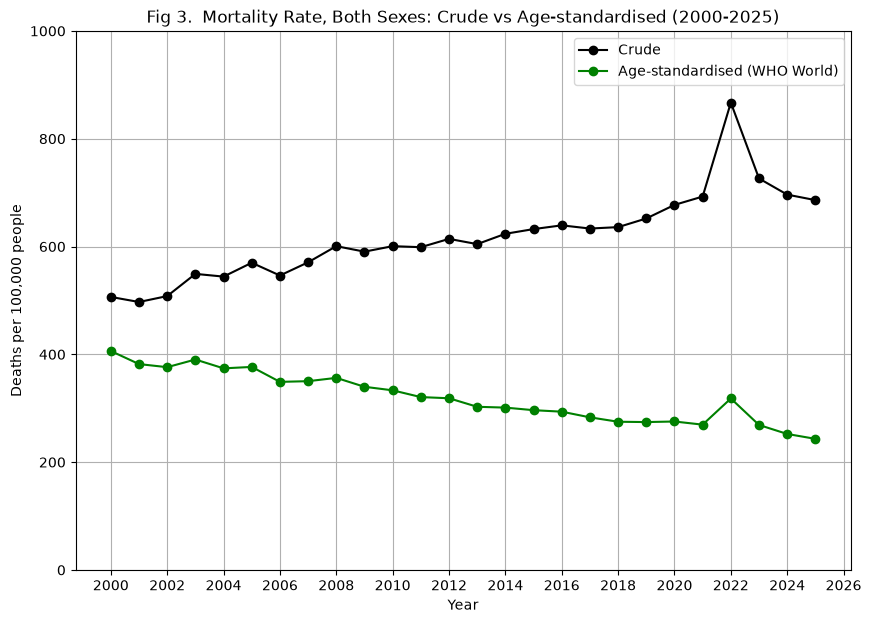

In [22]:
both_deaths = deaths_total[deaths_total['sex'] == 'Both sexes'].set_index('year')['deaths']
both_pop = pop_total[pop_total['sex'] == 'Both sexes'].set_index('year')['population']
crude_by_year = (both_deaths / both_pop * 100_000).to_dict()
                 
asr_by_year = {}
for yr, g in overall.groupby('year'):
    g = g.set_index('age').loc[AGE_ORDER]
    asr_by_year[yr] = (g['rate_per_100k'] * WHO_W).sum()


trend = pd.DataFrame({'crude': pd.Series(crude_by_year),
                      'asr': pd.Series(asr_by_year)})
trend.index.name = 'year'


fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(trend.index, trend['crude'], marker='o', label='Crude', color='black')
ax.plot(trend.index, trend['asr'], marker='o', label="Age-standardised (WHO World)", color='green')

ax.set_ylim(0, 1000)   # start at zero, see note below
ax.set_xticks(range(START_YEAR, END_YEAR + 2, 2))
ax.grid()

ax.legend()
ax.set_title(f"Fig 3.  Mortality Rate, Both Sexes: Crude vs Age-standardised ({START_YEAR}-{END_YEAR})")
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000 people")

### Comparing male vs female (2025)

Text(0, 0.5, 'Deaths per 100,000 (log scale)')

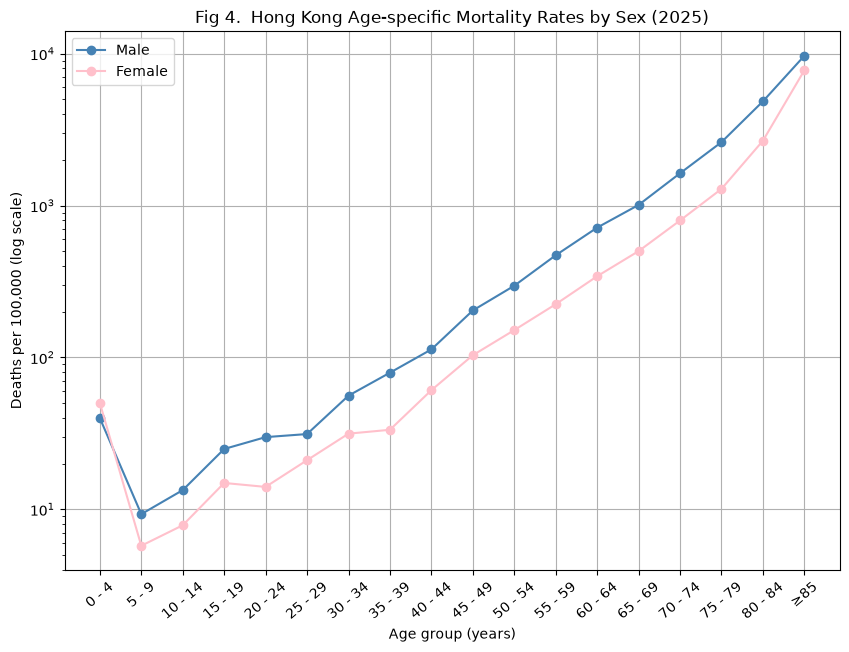

In [23]:
fig, ax = plt.subplots(figsize=(10,7))
for sex, color in [('Male', 'Steelblue'), ('Female', 'Pink')]:
    data = mortality[(mortality['year'] == END_YEAR) & (mortality['sex'] == sex)]
    data = data.set_index('age').loc[AGE_ORDER]
    ax.plot(
        range(len(AGE_ORDER)),
        data['rate_per_100k'],
        marker='o',
        label=sex,
        color=color
    )

ax.set_yscale('log')
ax.set_xticks(range(len(AGE_ORDER)), AGE_ORDER)
ax.tick_params(axis='x', rotation=40)
ax.grid()

ax.legend()
ax.set_title(f"Fig 4.  Hong Kong Age-specific Mortality Rates by Sex ({END_YEAR})")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Deaths per 100,000 (log scale)")

### Population pyramid over time (animation)

I want to show that moving visuals can sometimes be a nice way of showing data. The blob in the pyramid moves upward, and you can intuitively see the ageing pattern. That's the power of data visualisation.

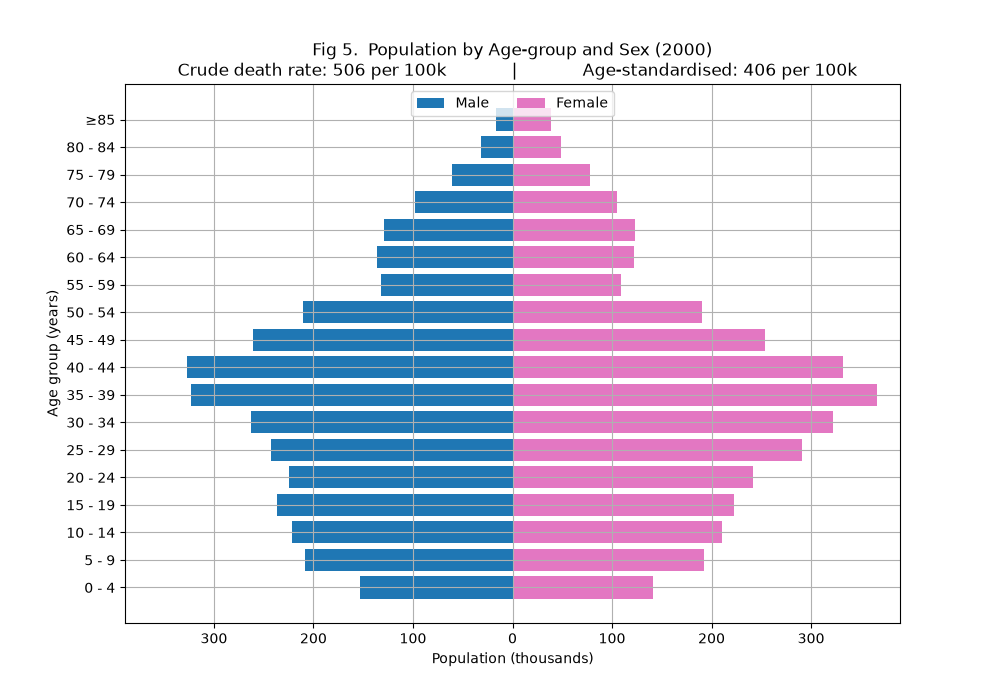

In [24]:
from matplotlib.ticker import FuncFormatter

pyramid = population[population['sex'].isin(['Male', 'Female'])]
pyr_wide = (
    pyramid.pivot_table(index=['year', 'age'], columns='sex', values='population', aggfunc='sum')
    .reset_index()
)
x_max = max(pyr_wide['Male'].max(), pyr_wide['Female'].max()) / 1000 * 1.05


fig, ax = plt.subplots(figsize=(10, 7))
ypos = np.arange(len(AGE_ORDER))

def draw_frame(year):
    ax.clear()
    one = pyr_wide[pyr_wide['year'] == year].set_index('age').reindex(AGE_ORDER)
    male = -one['Male'].to_numpy() / 1000
    female = one['Female'].to_numpy() / 1000
    ax.barh(ypos, male, color='tab:blue', label="Male")
    ax.barh(ypos, female, color='tab:pink', label="Female")
    ax.set_yticks(ypos, AGE_ORDER)
    ax.set_xlim(-x_max, x_max)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{abs(x):.0f}")) # prevent negative population for left side male
    ax.grid()

    ax.legend(loc='upper center', ncol=2)
    ax.set_title(
            f"Fig 5.  Population by Age-group and Sex ({year})\n"
            f"  Crude death rate: {crude_by_year[year]:.0f} per 100k             |             "
            f"Age-standardised: {asr_by_year[year]:.0f} per 100k"
        )
    ax.set_xlabel("Population (thousands)")
    ax.set_ylabel("Age group (years)")
    
anim = FuncAnimation(fig, draw_frame, frames=list(range(START_YEAR, END_YEAR + 1)))
anim.save("fig5_population_pyramid.gif", writer=PillowWriter(fps=1))
plt.close(fig)
Image(filename="population_pyramid.gif", embed=True)

In [25]:
print("Highest crude mortality rate year:", max(crude_by_year, key=crude_by_year.get))
print("Highest age-standardised mortality rate year:", max(asr_by_year, key=asr_by_year.get))

Highest crude mortality rate year: 2022
Highest age-standardised mortality rate year: 2000


## Findings

- **Crude mortality rate increases** generally, but if we use the **standardised mortality rate** (against WHO's standard 2000-2025), it's actually **decreasing**.
- During 2000-2025, 2022 had the highest total deaths and crude death rate. I don't have data to support the cause so I shouldn't mention here (but it was related to **COVID-19**!).

## Limitations

- The analysis is descriptive.
- WHO is one choice of standard population.
- In young age groups, there are very small numbers of deaths.
